# CS 746 | Data Exploration

Benign and malicious DNS-over-HTTPS traffic. Source: CIRA-CIC-DoHBrw-2020; selected Cloudflare and DNSCat2 subsets.

## 1. Load data

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
DATA_DIR = Path.cwd()
benign = pd.read_csv(DATA_DIR / "normal_doh_traffic_cloudflare_server (1).csv")
malicious = pd.read_csv(DATA_DIR / "dnscat2_data_4 (1).csv")
benign["traffic_class"] = "Benign"
malicious["traffic_class"] = "Malicious"
df = pd.concat([benign, malicious], ignore_index=True)
features = [c for c in df.select_dtypes(include="number") if c != "is_doh" and df[c].nunique(dropna=True) > 1]
print("Dataset shape:", df.shape)
print(df["traffic_class"].value_counts().to_string())
display(df.head())

Dataset shape: (12648, 18)
traffic_class
Malicious    10298
Benign        2350


,bytes_out,num_pkts_out,bytes_in,num_pkts_in,bytes_ration,num_pkts_ration,time,av_pkt_size_in,av_pkt_size_out,var_pkt_size_in,var_pkt_size_out,median_in,median_out,mindelay,avgdelay,maxdelay,is_doh,traffic_class
0,0.038207,0.040566,0.037993,0.042252,0.330945,0.666667,0.142261,0.161100,0.446486,0.029621,0.089444,0.271106,0.446486,0.0,0.156132,0.138663,1,Benign
1,0.158368,0.164492,0.157195,0.165296,0.330548,0.643651,0.368210,0.179073,0.482115,0.031426,0.088050,0.286723,0.482115,0.0,0.101448,0.138796,1,Benign
2,0.444930,0.461775,0.413861,0.452236,0.309801,0.627386,0.999888,0.166632,0.483418,0.026398,0.095197,0.275913,0.483418,0.0,0.099373,0.138832,1,Benign
3,0.132261,0.153362,0.135935,0.157628,0.342253,0.658327,0.999999,0.148324,0.312008,0.036691,0.085530,0.260006,0.312008,0.0,0.292235,0.193173,1,Benign
4,0.129911,0.151098,0.133228,0.155072,0.341502,0.657356,0.999391,0.147198,0.307559,0.035029,0.083906,0.259027,0.307559,0.0,0.296651,0.138849,1,Benign


### Interpretation: Dataset overview

The analysis combines two selected subsets of the CIRA-CIC-DoHBrw-2020 dataset: 2,350 benign Cloudflare DoH flow records and 10,298 malicious DNSCat2-associated flow records, for 12,648 records in total. The flow-level features allow comparisons of traffic volume, connection duration, packet sizes, and timing without examining encrypted DNS payloads. The labels describe these specific collection scenarios, not all benign or malicious DoH activity.


## 2. Data quality

In [16]:
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Constant numeric features:", [c for c in df.select_dtypes(include="number") if df[c].nunique(dropna=True) <= 1])
print("Analyzed features:", len(features))
display(df.groupby("traffic_class")[features].agg(["median", "mean", "std"]).round(4))

Missing values: 0
Exact duplicate rows: 57
Constant numeric features: ['mindelay']
Analyzed features: 15


bytes_out                 num_pkts_out                 bytes_in  \
                 median    mean     std       median    mean     std   median   
traffic_class                                                                   
Benign           0.0005  0.0273  0.0792       0.0005  0.0306  0.0839   0.0010   
Malicious        0.0381  0.1512  0.2464       0.0348  0.1421  0.2370   0.0326   

                              num_pkts_in  ... median_in median_out          \
                 mean     std      median  ...       std     median    mean   
traffic_class                              ...                                
Benign         0.0259  0.0770      0.0004  ...    0.3184     0.4133  0.3417   
Malicious      0.1485  0.2428      0.0241  ...    0.0173     0.2160  0.1992   

                      avgdelay                 maxdelay                  
                  std   median    mean     std   median    mean     std  
traffic_class                                                            
Benign         0.1321   0.2011  0.2348  0.1707   0.1364  0.1184  0.0819  
Malicious      0.0411   0.0077  0.0348  0.0527   0.1339  0.1019  0.0618  

[2 rows x 45 columns]

### Interpretation: Data quality

The dataset contains no missing values. The audit flags 57 exact duplicate rows; these are retained because identical feature measurements do not necessarily represent erroneous network flows. `mindelay` is constant and is excluded from the variable-feature analysis, leaving 15 nonconstant numeric features. The source feature values appear to be scaled or transformed, so differences are interpreted relatively rather than as original bytes, packets, or seconds until their units are verified.


## 3. Class distribution

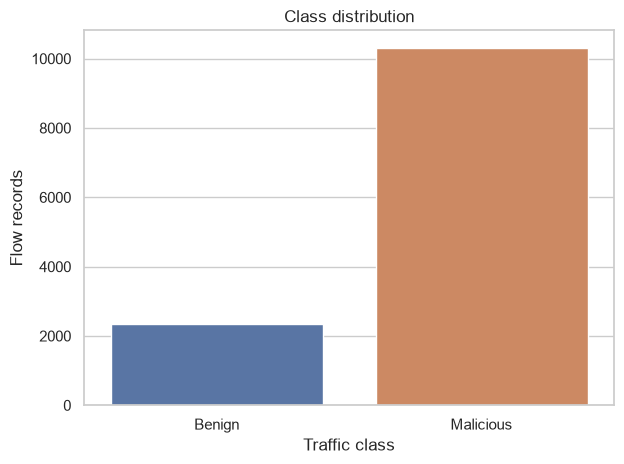

In [17]:
ax = sns.countplot(data=df, x="traffic_class", order=["Benign", "Malicious"], hue="traffic_class", legend=False)
ax.set(xlabel="Traffic class", ylabel="Flow records", title="Class distribution")
plt.tight_layout()
plt.show()

### Interpretation: Class distribution

The selected dataset is imbalanced: 10,298 records (approximately 81.4%) are malicious and 2,350 (approximately 18.6%) are benign. These proportions describe the chosen research samples, not the prevalence of malicious DoH on real networks. All records are retained for descriptive comparisons; balanced sampling is used only for the pairplot to make both classes visible.


## 4. Feature distributions

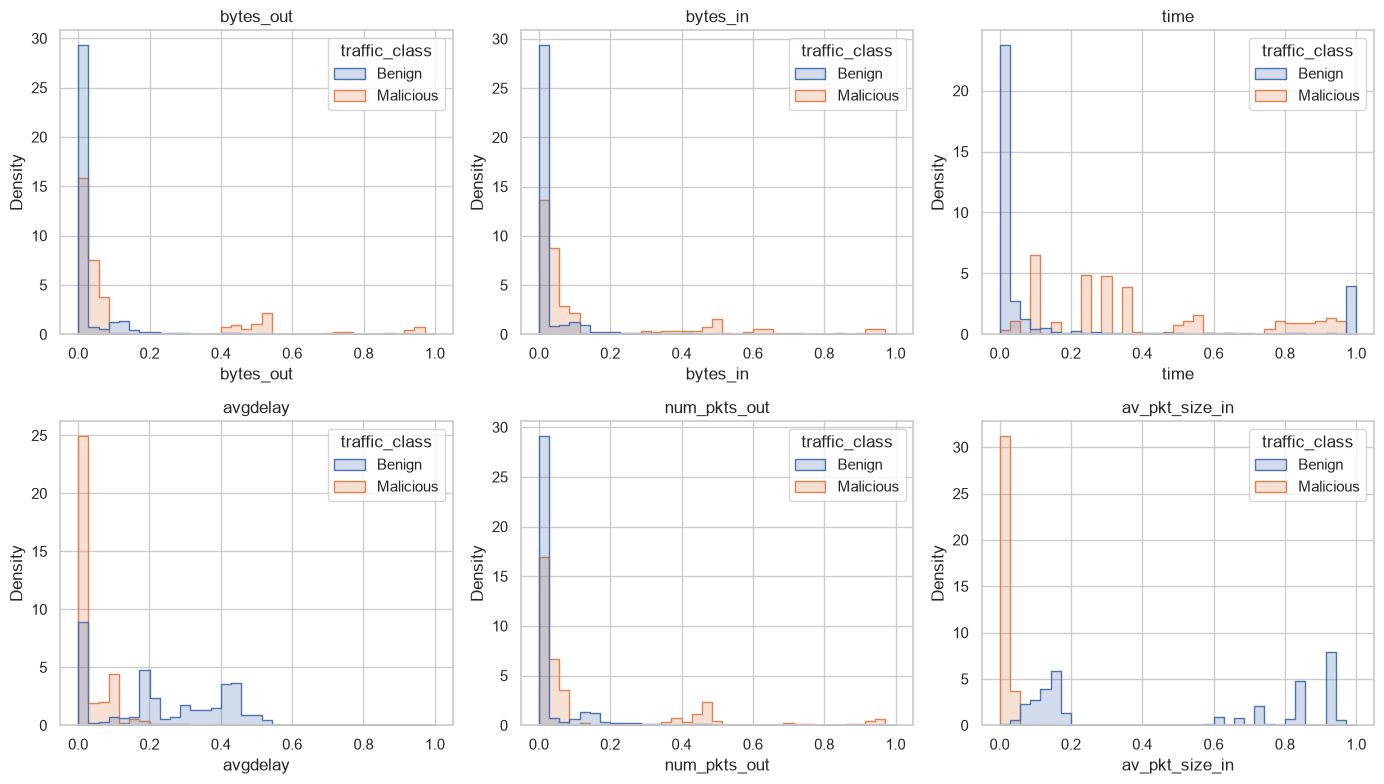

In [18]:
preferred = ["bytes_out", "bytes_in", "time", "avgdelay", "num_pkts_out", "av_pkt_size_in"]
selected = [c for c in preferred if c in features][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, selected):
    sns.histplot(data=df, x=col, hue="traffic_class", stat="density", common_norm=False, element="step", bins=35, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interpretation: Feature distributions

The histograms show how selected traffic-volume, duration, and timing measurements vary within each class. The descriptive statistics show a higher median `bytes_out` value for the malicious subset (approximately 0.0381) than for the benign subset (approximately 0.0005). Conversely, the benign subset has a higher median `avgdelay` (approximately 0.2011 versus 0.0077). These are descriptive differences in the recorded feature scale; the statistical-analysis notebook will assess their significance and effect sizes.


## 5. Feature comparison

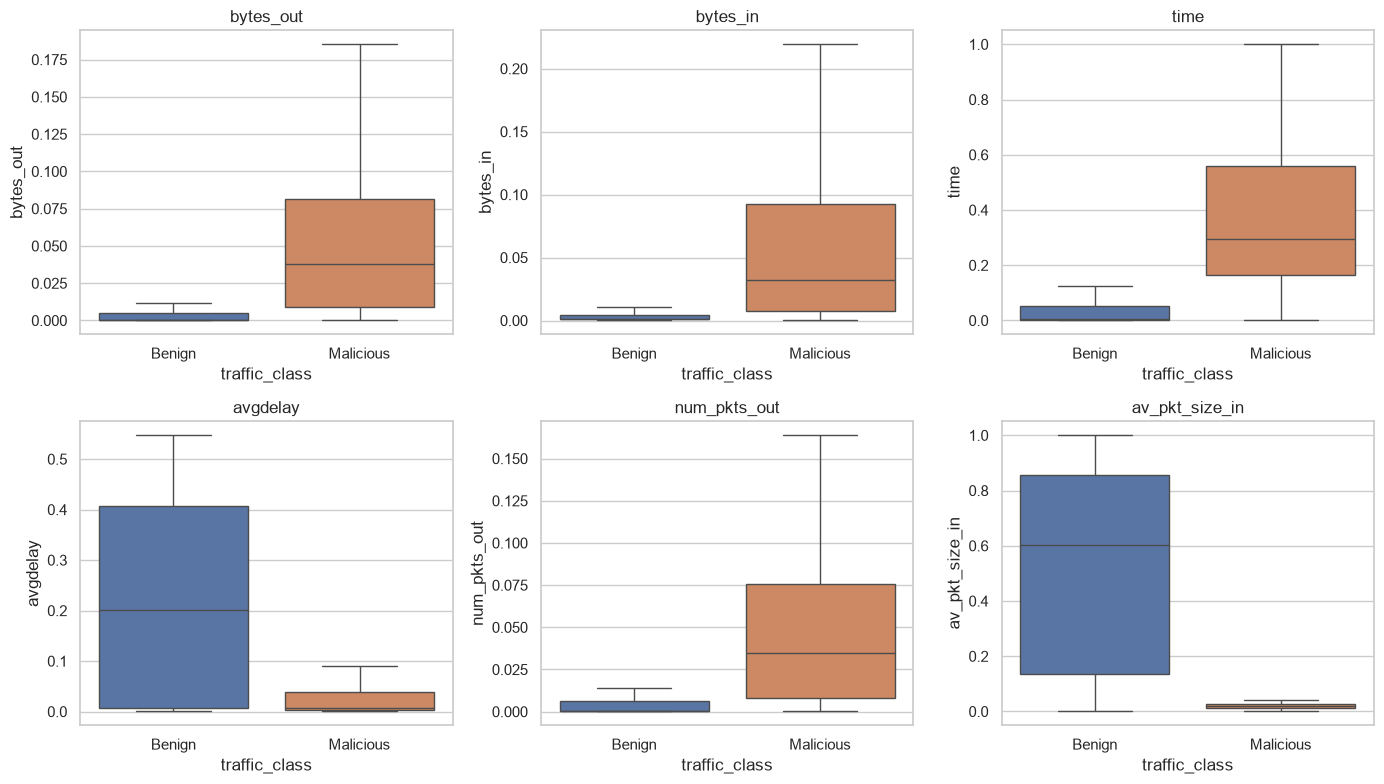

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, selected):
    sns.boxplot(data=df, x="traffic_class", y=col, order=["Benign", "Malicious"], hue="traffic_class", legend=False, showfliers=False, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interpretation: Feature comparison

The boxplots compare class-specific medians and interquartile ranges for the selected features. Differences in central tendency and spread suggest that traffic-volume and timing characteristics may distinguish the two collection scenarios. Outlier symbols are hidden to improve readability; the corresponding observations remain in the data and are not excluded from the statistical analysis. Visual separation alone does not establish statistical significance or classification performance.


## 6. Spearman correlation

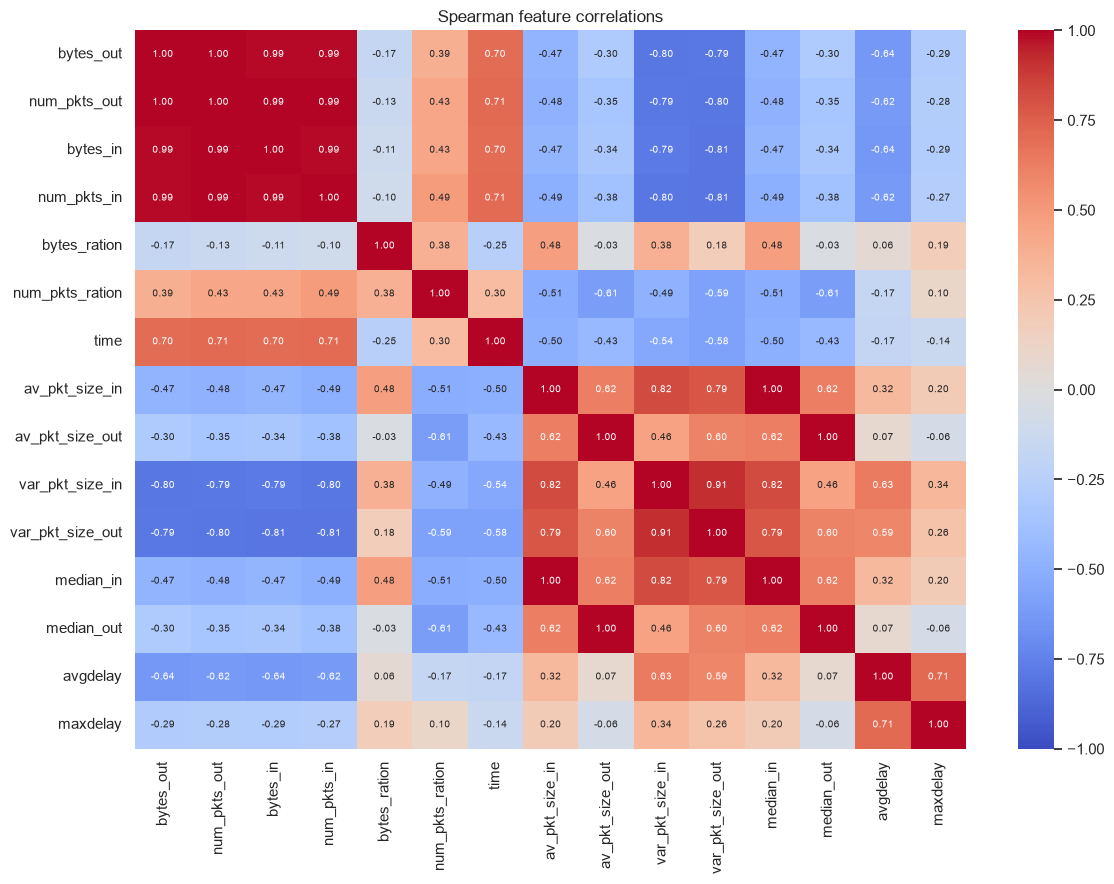

In [20]:
corr = df[features].corr(method="spearman")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman feature correlations")
plt.tight_layout()
plt.show()

### Interpretation: Spearman correlation

Spearman rank correlation summarizes monotonic relationships among the 15 nonconstant numeric features. The heatmap helps identify related measurements and potential redundancy, particularly among byte-count and packet-count variables. Correlation measures association between features, not causation, and does not by itself establish that a feature distinguishes the two traffic classes. Individual correlation strengths should be interpreted from the displayed coefficients.


## 7. Multivariate relationships

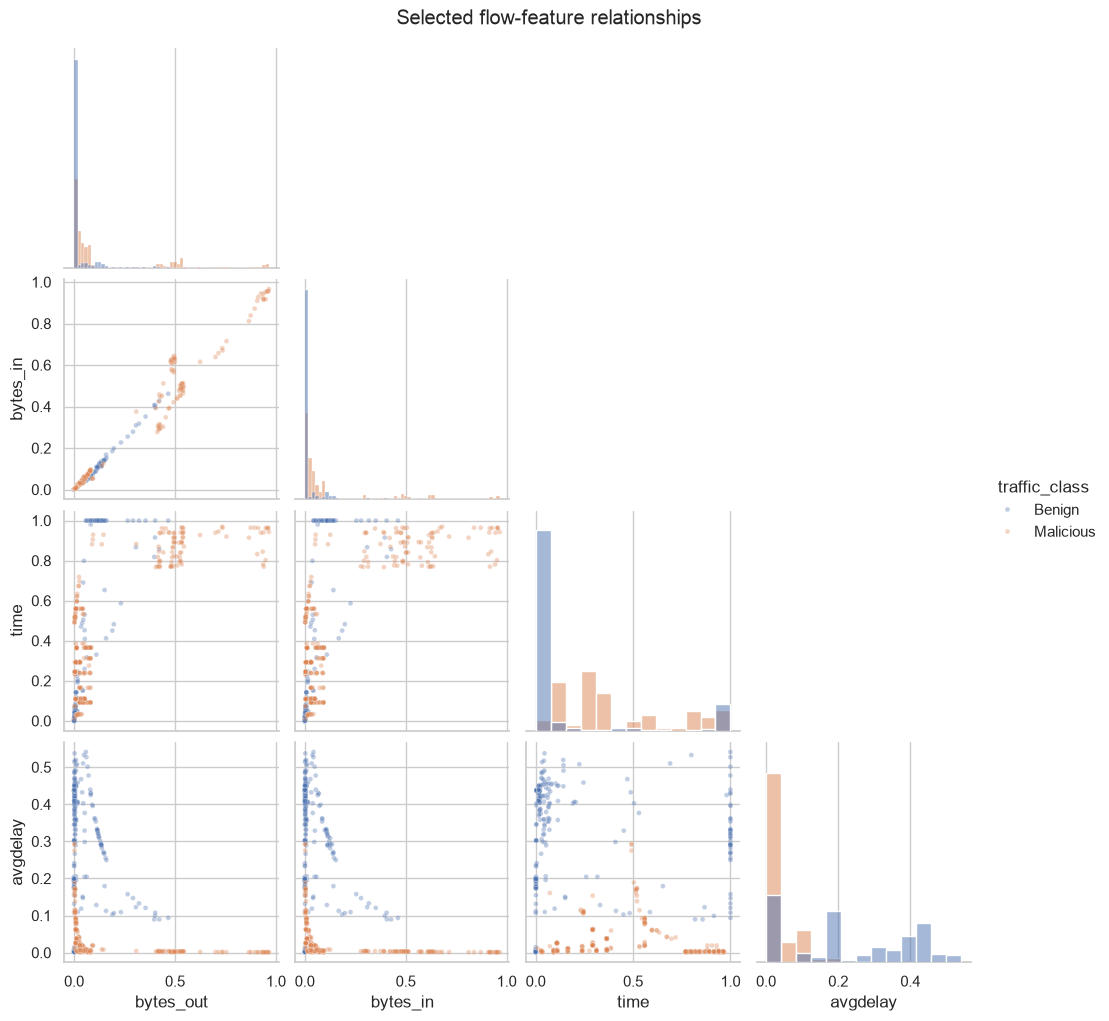

In [21]:
selected_pair = selected[:4]
if len(selected_pair) >= 2:
    samples = []
    for label in ("Benign", "Malicious"):
        subset = df.loc[df["traffic_class"] == label, selected_pair + ["traffic_class"]]
        samples.append(subset.sample(n=min(400, len(subset)), random_state=42))
    viz = pd.concat(samples, ignore_index=True)
    grid = sns.pairplot(viz, vars=selected_pair, hue="traffic_class", corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 12})
    grid.fig.suptitle("Selected flow-feature relationships", y=1.02)
    plt.show()

### Interpretation: Multivariate relationships

The pairplot explores joint patterns among `bytes_out`, `bytes_in`, `time`, and `avgdelay`. It uses a reproducible **balanced visualization sample** of up to 400 flows from each class; it does not preserve the original class proportions. The diagonal plots compare individual distributions, while the scatterplots reveal overlap and possible group structure. Apparent separation is exploratory and should not be interpreted as measured predictive accuracy.


## Exploratory data analysis summary

The analysis examined 12,648 selected DoH flow records (2,350 benign Cloudflare and 10,298 malicious DNSCat2). Quality checks found no missing values, flagged 57 exact duplicates, and identified one constant feature (`mindelay`), leaving 15 varying numeric features for exploration. Descriptive summaries and visualizations indicate differences in recorded traffic-volume and timing characteristics, including higher median `bytes_out` in the malicious subset and higher median `avgdelay` in the benign subset. These patterns motivate formal Mann–Whitney U tests, Cliff's delta effect sizes, and Benjamini–Hochberg false-discovery-rate correction in the companion statistical-analysis notebook. Findings apply to these selected traffic scenarios and should not be generalized to all DoH traffic. PCAP extraction is a proposed preprocessing step and is not claimed as completed here.
